# ML-06 — Signal Audit: Do the Flags Hold?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/saibalaji2004/Flyrank-intern-repo/blob/main/work/notebooks/w04_signal_audit.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Distributions

*Look before deciding: distributions of your key fields. Note the heavy tails.*

### Distribution findings

The distribution audit examines search impressions, clicks, sessions, content age, update recency, average search position, and click-through rate. Traffic and visibility measurements may be heavily right-skewed because a small number of pages can receive substantially more activity than most pages. Log-scaled histograms help make these differences easier to inspect, while medians and percentiles provide context that averages alone may hide.

These distributions describe the supplied dataset. They do not establish why a page's performance changes or prove that updating a page will improve its results.

Dataset shape: (30000, 45)

Numeric field distributions:
                          count     mean       std   min    25%     50%  \
impressions_90d         30000.0  5200.37  16838.02   1.0   81.0  731.00   
clicks_90d              30000.0    16.10     75.08   0.0    0.0    1.00   
sessions_90d            30000.0    37.07    107.07   1.0    2.0    7.00   
days_since_last_update  30000.0    46.10     42.08   1.0   20.0   20.00   
content_age_days        30000.0   256.17    132.71  90.0  132.0  236.00   
avg_position            30000.0    16.34     15.22   0.0    6.2   10.80   
ctr                     30000.0     0.51      3.28   0.0    0.0    0.07   

                            75%       90%       95%       99%       max  
impressions_90d         3615.25  12136.40  22996.50  73505.83  517715.0  
clicks_90d                 7.00     32.00     69.05    253.01    4178.0  
sessions_90d              27.00     88.00    166.00    451.01    4345.0  
days_since_last_update   104.00    104.00    1

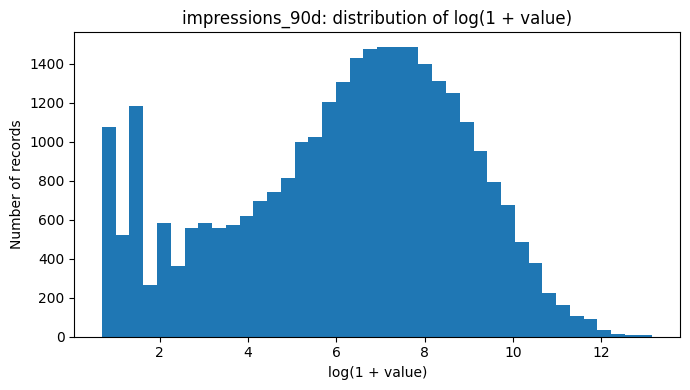

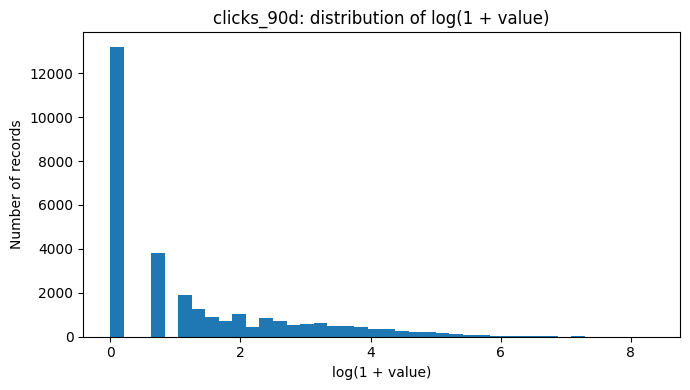

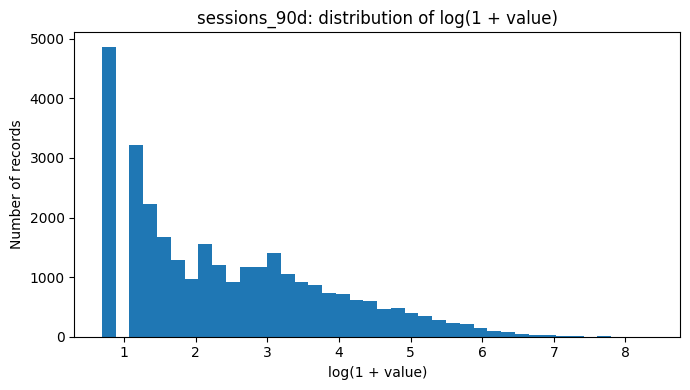


Distribution audit completed.


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the anonymized starter dataset
dataset_url = (
    "https://raw.githubusercontent.com/saibalaji2004/"
    "Flyrank-intern-repo/main/data/raw/content_refresh_anonymized.csv"
)
df = pd.read_csv(dataset_url)

# Create the observed decline label
df["is_declining_label"] = (
    df["trend_direction"].eq("down").astype(int)
)

# Inspect key numeric fields
key_fields = [
    "impressions_90d",
    "clicks_90d",
    "sessions_90d",
    "days_since_last_update",
    "content_age_days",
    "avg_position",
    "ctr",
]

available_fields = [
    col for col in key_fields if col in df.columns
]

print("Dataset shape:", df.shape)
print("\nNumeric field distributions:")
print(
    df[available_fields]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
    .T.round(2)
)

print("\nMissing values:")
print(df[available_fields].isna().sum())

print("\nDecline label distribution:")
print(df["is_declining_label"].value_counts())

# Plot distributions using log scaling where useful
for col in [
    "impressions_90d",
    "clicks_90d",
    "sessions_90d",
]:
    if col in df.columns:
        values = df[col].dropna()
        values = values[values >= 0]

        plt.figure(figsize=(7, 4))
        plt.hist(np.log1p(values), bins=40)
        plt.title(f"{col}: distribution of log(1 + value)")
        plt.xlabel("log(1 + value)")
        plt.ylabel("Number of records")
        plt.tight_layout()
        plt.show()

print("\nDistribution audit completed.")

## 2. Signal test #1 / #2 / #3 (verdict each)

*Three safe signals, each with a mini-test and a verdict: CONFIRMED / OPPOSITE / MIXED / FALSE.*

### Signal tests and verdicts

**Signal 1: Content update recency and decline**

Compare the observed decline rate for pages updated within the last 90 days with the rate for pages not updated within the last 90 days. The result tests whether update recency alone is a reliable review signal. A relationship in this dataset does not prove that updating a page causes better performance.

**Signal 2: Search visibility and decline**

Compare observed decline rates across low- and high-impression pages, using the median of positive `impressions_90d` as the threshold. This tests whether visibility helps distinguish pages for review, while recognizing that high impressions do not necessarily mean good performance.

**Signal 3: Average position and click-through rate**

Compare median CTR across search-position bands. Position zeros are treated as unavailable and excluded from this comparison. This tests whether the observed CTR pattern varies with search position without assuming that position alone explains clicks.

In [6]:
# Signal tests using observed dataset values

# Signal 1: Update recency vs observed decline
df["update_group"] = np.where(
    df["days_since_last_update"] < 90,
    "Updated <90 days",
    "Not updated <90 days"
)

signal1 = (
    df.groupby("update_group", observed=True)["is_declining_label"]
    .agg(records="size", decline_rate="mean")
)
signal1["decline_rate_pct"] = signal1["decline_rate"] * 100

print("SIGNAL 1: Update recency vs decline")
print(signal1.round(3))

# Signal 2: Visibility vs observed decline
positive_impressions = df.loc[
    df["impressions_90d"] > 0, "impressions_90d"
]
visibility_threshold = positive_impressions.median()

df["visibility_group"] = np.where(
    df["impressions_90d"] >= visibility_threshold,
    "Higher visibility",
    "Lower visibility"
)

signal2 = (
    df.groupby("visibility_group", observed=True)["is_declining_label"]
    .agg(records="size", decline_rate="mean")
)
signal2["decline_rate_pct"] = signal2["decline_rate"] * 100

print("\nSIGNAL 2: Visibility vs decline")
print("Positive-impression median threshold:", visibility_threshold)
print(signal2.round(3))

# Signal 3: Position bands vs median CTR
position_df = df.loc[df["avg_position"] > 0].copy()

position_df["position_band"] = pd.cut(
    position_df["avg_position"],
    bins=[0, 3, 10, 20, 100, np.inf],
    labels=["1-3", "4-10", "11-20", "21-100", ">100"],
    include_lowest=True
)

signal3 = (
    position_df.groupby("position_band", observed=True)["ctr"]
    .agg(records="size", median_ctr="median", mean_ctr="mean")
)

print("\nSIGNAL 3: Position band vs CTR")
print(signal3.round(3))

print("\nAll three signal tests completed.")

SIGNAL 1: Update recency vs decline
                      records  decline_rate  decline_rate_pct
update_group                                                 
Not updated <90 days     9345         0.608            60.845
Updated <90 days        20655         0.512            51.203

SIGNAL 2: Visibility vs decline
Positive-impression median threshold: 731.0
                   records  decline_rate  decline_rate_pct
visibility_group                                          
Higher visibility    15007         0.594            59.399
Lower visibility     14993         0.490            49.010

SIGNAL 3: Position band vs CTR
               records  median_ctr  mean_ctr
position_band                               
1-3               1141        0.00     2.714
4-10             11842        0.16     0.651
11-20             7273        0.10     0.323
21-100            8524        0.00     0.212
>100                15        0.00     0.000

All three signal tests completed.


### Signal test results and verdicts

**Signal 1: Update recency vs. decline — CONFIRMED**

Pages not updated within the last 90 days had an observed decline rate of 60.85%, compared with 51.20% for pages updated within the last 90 days. The difference is approximately 9.64 percentage points. Update recency is a useful directional review signal in this dataset, but this association does not prove that updating content prevents decline.

**Signal 2: Search visibility vs. decline — CONFIRMED**

Pages with at least 731 impressions over 90 days had an observed decline rate of 59.40%, compared with 49.01% for pages below the threshold. The difference is approximately 10.39 percentage points. Higher visibility may help prioritize pages with meaningful exposure, but it does not establish that those pages are declining because of poor content.

**Signal 3: Average position vs. CTR — MIXED**

Median CTR was 0.16 for positions 4–10 and 0.10 for positions 11–20, while the median was zero for positions 1–3 and 21–100. Mean CTR generally decreased across the broader position bands, but the top-position band did not have a higher median CTR than positions 4–10. Position alone is therefore insufficient to determine which page should be reviewed.

These are descriptive findings from the supplied dataset, not causal conclusions or guarantees of future performance.

## 3. The flag-linked test

*Pick a signal one of FlyRank's real flags relies on. Does the data support the rule's assumption?*

### Flag-linked test: staleness assumption

The baseline treats a page that has not been updated for at least 90 days as stale. To test this assumption, compare the observed decline rate for pages meeting this threshold with the rate for more recently updated pages. The comparison evaluates whether the flag separates groups with different observed decline rates; it does not prove that the threshold is optimal or that a refresh will improve results.

In [7]:
# Test the staleness flag used by the Week-4 baseline

df["is_stale_90d"] = df["days_since_last_update"] >= 90

staleness_test = (
    df.groupby("is_stale_90d", observed=True)["is_declining_label"]
    .agg(records="size", decline_rate="mean")
)

staleness_test["decline_rate_pct"] = (
    staleness_test["decline_rate"] * 100
)

print("Staleness flag test:")
print(staleness_test.round(3))

stale_rate = staleness_test.loc[True, "decline_rate"]
recent_rate = staleness_test.loc[False, "decline_rate"]
difference_pp = (stale_rate - recent_rate) * 100

print(f"\nDecline-rate difference: {difference_pp:.2f} percentage points")

if difference_pp > 0:
    print("Verdict: CONFIRMED directionally in this dataset.")
elif difference_pp < 0:
    print("Verdict: OPPOSITE direction in this dataset.")
else:
    print("Verdict: MIXED; no observed difference.")

print("Caution: this test does not establish causality or an optimal threshold.")

Staleness flag test:
              records  decline_rate  decline_rate_pct
is_stale_90d                                         
False           20655         0.512            51.203
True             9345         0.608            60.845

Decline-rate difference: 9.64 percentage points
Verdict: CONFIRMED directionally in this dataset.
Caution: this test does not establish causality or an optimal threshold.


## 4. What this means in practice

*Two or three sentences: what a content team should take from this.*

### Practical implications

Content teams can use update recency and search visibility together to prioritize pages for human review, because both signals were associated with higher observed decline rates in this dataset. CTR and average position provide additional context, but neither should be used alone to decide whether a page needs refreshing. These signals support review prioritization, not causal claims or guarantees that a content update will improve search performance.

In [8]:
print("Practical implications documented.")
print("Use signals for human review, not automatic refresh decisions.")

Practical implications documented.
Use signals for human review, not automatic refresh decisions.


## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.